# Notebook 05: Uncertainty Quantification & Exploration Target Prioritization (Phases 7 & 8)
**Objectives:**
1. Quantify **epistemic model uncertainty** (via Spatial Block Bootstrapping) and **aleatoric measurement sensitivity** (via Monte Carlo covariate perturbation).
2. Construct bivariate **Prospectivity vs. Uncertainty maps** ($\mathbb{E}[p(s)]$ vs. $\text{SD}[p(s)]$) and 90% confidence intervals.
3. Categorize the study area into actionable **Exploration Priority Tiers (Priority 1, Priority 2, Priority 3, Background)** to support geologist decision-making and generate an interactive **Folium** web map.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

PROJECT_ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data.acquisition import generate_zambia_prospectivity_benchmark, load_config
from src.data.cleaning import validate_and_standardize_geodata
from src.features.spatial_features import engineer_geospatial_features
from src.models.spatial_cv import assign_spatial_blocks
from src.models.train_evaluate import build_candidate_models
from src.models.uncertainty import (
    classify_uncertainty_quadrants_and_targets,
    run_spatial_bootstrap_uncertainty,
)
from src.visualization.maps import (
    create_interactive_folium_target_map,
    plot_prospectivity_uncertainty_and_targets,
)

config = load_config(PROJECT_ROOT / "configs" / "config.yaml")
raw_gdf, faults_gdf = generate_zambia_prospectivity_benchmark(config)
clean_gdf, _ = validate_and_standardize_geodata(raw_gdf, target_crs=config["crs"]["projected_crs"])
feat_gdf, feature_cols = engineer_geospatial_features(clean_gdf, faults_gdf)
modeling_features = [c for c in feature_cols if c != "cu_co_log_ratio"]
feat_gdf["spatial_block_id"] = assign_spatial_blocks(
    feat_gdf, block_size_m=config["validation"]["spatial_block_size_m"]
)

## 1. Spatial Block Bootstrap + Monte Carlo Uncertainty Propagation
> *"A high predicted probability does not necessarily mean mineralization exists. It represents a model-based estimate based on available evidence and assumptions."*

In [2]:
y = feat_gdf["mineral_occurrence"].to_numpy()
pos_weight = float(np.sqrt((len(y) - y.sum()) / max(y.sum(), 1)))
models = build_candidate_models(pos_weight=pos_weight, seed=config["project"]["random_seed"])

unc_gdf = run_spatial_bootstrap_uncertainty(
    feat_gdf,
    feature_cols=modeling_features,
    target_col="mineral_occurrence",
    base_pipeline=models["XGBoost"],
    block_col="spatial_block_id",
    n_bootstraps=60,
    mc_noise_std=0.05,
    seed=config["project"]["random_seed"],
)

prioritized_gdf = classify_uncertainty_quadrants_and_targets(unc_gdf)

# Summary table by Exploration Priority Tier
priority_summary = (
    prioritized_gdf.groupby("exploration_priority")
    .agg(
        cell_count=("sample_id", "count"),
        area_share_pct=("sample_id", lambda s: round(100.0 * len(s) / len(prioritized_gdf), 2)),
        mean_prospectivity=("prob_mean", "mean"),
        mean_uncertainty_sd=("prob_std", "mean"),
        known_occurrences_captured=("mineral_occurrence", "sum"),
        median_cu_ppm=("cu_ppm", "median"),
    )
    .sort_values("mean_prospectivity", ascending=False)
)
display(priority_summary)

,cell_count,area_share_pct,mean_prospectivity,mean_uncertainty_sd,known_occurrences_captured,median_cu_ppm
exploration_priority,,,,,,
Priority 1: High Prospectivity + High Confidence,58,2.32,0.776597,0.103971,44,120.49
Priority 2: High Prospectivity + Moderate Uncertainty,162,6.48,0.459477,0.143489,72,56.44
Priority 3: Favorable Geological Signals + Data Gap,393,15.72,0.243991,0.105712,77,41.06
Background: Low Prospectivity,1887,75.48,0.078125,0.037332,13,25.15


## 2. Prospectivity, Uncertainty, and Candidate Exploration Target Maps

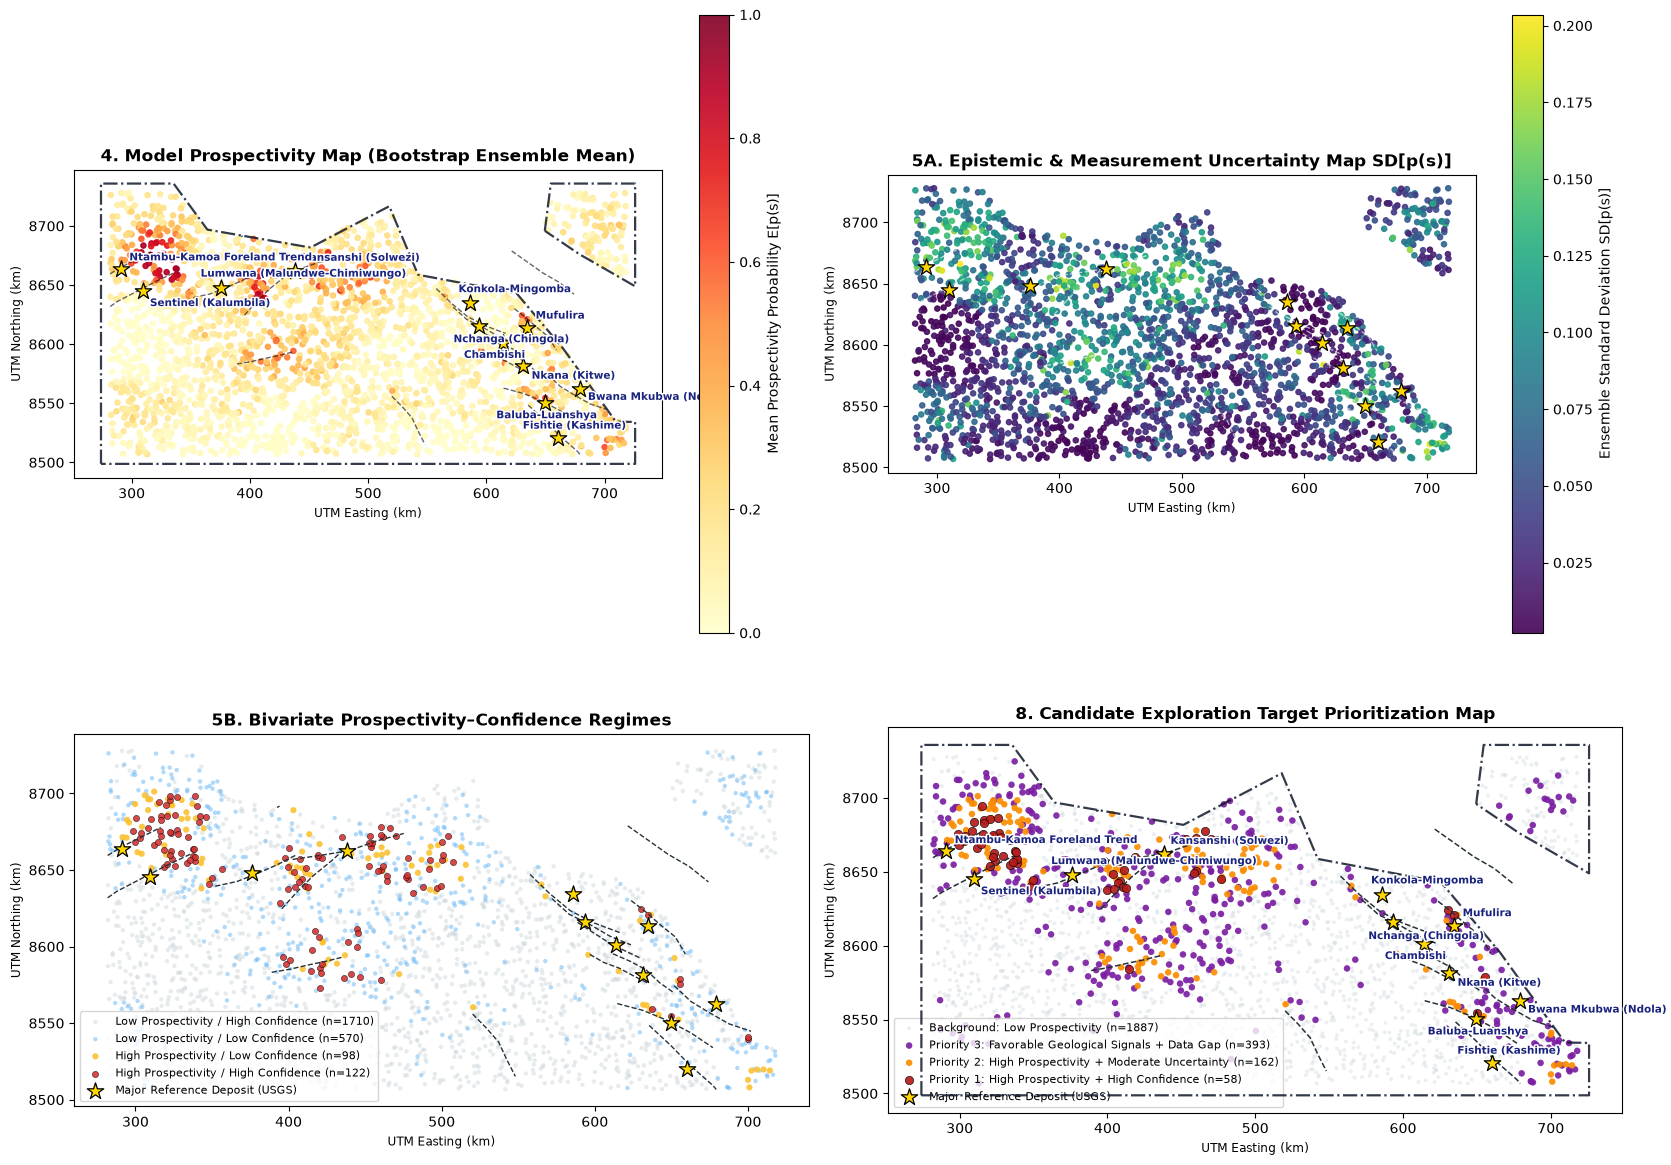

Saved interactive Folium map to: C:\Users\JSONGA5\Desktop\kobold\data\processed\zambia_exploration_targets_interactive.html


In [3]:
fig4 = plot_prospectivity_uncertainty_and_targets(
    prioritized_gdf,
    faults_gdf,
    save_path=PROJECT_ROOT / "data" / "processed" / "fig04_prospectivity_uncertainty_targets.png",
)
plt.show()

# Generate interactive Folium HTML map
html_map_path = PROJECT_ROOT / "data" / "processed" / "zambia_exploration_targets_interactive.html"
_ = create_interactive_folium_target_map(prioritized_gdf, faults_gdf, html_map_path)
print(f"Saved interactive Folium map to: {html_map_path}")